# Workshop 3 - LLMs

**Before you start:** *Runtime → Change runtime type → T4 GPU*. The notebook also runs on CPU, only slower.

We use one pair of models in all sections: **Qwen2.5-0.5B** (the base model, after pretraining only) and **Qwen2.5-0.5B-Instruct** (the same model after post-training).

## 0 - Setup

In [50]:
# Setup: install peft (LoRA, section 5) and load the two models
!pip -q install peft
!pip install -U torchao

import math, random, time, copy
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from transformers import AutoModelForCausalLM, AutoTokenizer

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', DEVICE, '|', torch.cuda.get_device_name(0) if DEVICE == 'cuda' else 'no GPU')

BASE_ID, INSTRUCT_ID = 'Qwen/Qwen2.5-0.5B', 'Qwen/Qwen2.5-0.5B-Instruct'
tok = AutoTokenizer.from_pretrained(INSTRUCT_ID)          # the two models share the same tokenizer

base = AutoModelForCausalLM.from_pretrained(BASE_ID).to(DEVICE, torch.float32).eval()
inst = AutoModelForCausalLM.from_pretrained(INSTRUCT_ID).to(DEVICE, torch.float32).eval()
for m in (base, inst):                                    # built-in generate(): greedy, unless we ask for sampling
    m.generation_config.do_sample = False
    m.generation_config.temperature = m.generation_config.top_p = m.generation_config.top_k = None

V = len(tok)
print(f'parameters: {sum(p.numel() for p in base.parameters()) / 1e6:.0f} M')
print(f'vocabulary: {V:,} tokens')

device: cuda | Tesla T4


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

parameters: 494 M
vocabulary: 151,665 tokens


## 1 - Loss and perplexity

One forward pass gives a distribution over the vocabulary at **every** position. The loss is the mean of $-\log p$ of the true next token:

$$L = \frac{1}{T}\sum_{t} -\log \hat{y}_t[w_{t+1}] \qquad \text{PPL} = e^{L}$$

In [17]:
text = 'So long, and thanks for all the fish.'
ids = tok(text, return_tensors='pt').input_ids.to(DEVICE)          # (1, T)

with torch.no_grad():
    out = base(ids, labels=ids)                # Hugging Face computes the loss when we give labels

pred   = out.logits[:, :-1, :]                 # the prediction at position t ...
target = ids[:, 1:]                            # ... is scored against the token at position t+1
loss = F.cross_entropy(pred.reshape(-1, pred.shape[-1]), target.reshape(-1))

print('logits shape   :', tuple(out.logits.shape), '= (batch, positions, vocabulary)')
print(f'our loss       : {loss.item():.4f}')
print(f'model loss     : {out.loss.item():.4f}')
print(f'perplexity     : {math.exp(loss.item()):.1f}')
print(f'random weights : loss = ln(V) = {math.log(V):.2f}, perplexity = {V:,}')

logits shape   : (1, 10, 151936) = (batch, positions, vocabulary)
our loss       : 2.0107
model loss     : 2.0107
perplexity     : 7.5
random weights : loss = ln(V) = 11.93, perplexity = 151,665


**What to look at:** our loss and the model loss are the same number. The trained model's perplexity is far below the 151,665 of a uniform guess: at each token it hesitates between < 10 choices.

In [19]:
# Pretraining loss: only the probability of the true next token counts
probs = F.softmax(pred[0], dim=-1)
p_true = probs[torch.arange(target.shape[1]), target[0]]
first_choice = probs.argmax(-1)

print(f"{'context ends with':>18} | {'true next':<14} {'p':>6} {'-log p':>7} | model's first choice")
for t in range(target.shape[1]):
    print(f'{tok.decode(ids[0, t]):>18} | {tok.decode(target[0, t]):<14} '
          f'{p_true[t].item():6.3f} {-math.log(p_true[t].item()):7.2f} | {tok.decode(first_choice[t])}')
print(f"{'':>18}   {'mean of -log p':<14} {'':>6} {-p_true.log().mean().item():7.2f}   <- the loss above")

 context ends with | true next           p  -log p | model's first choice
                So |  long           0.001    6.87 |  I
              long | ,               0.144    1.94 |  as
                 , |  and            0.019    3.96 |  the
               and |  thanks         0.468    0.76 |  thanks
            thanks |  for            0.883    0.12 |  for
               for |  all            0.748    0.29 |  all
               all |  the            0.825    0.19 |  the
               the |  fish           0.107    2.23 |  laughs
              fish | .               0.177    1.73 | .
                     mean of -log p           2.01   <- the loss above


**What to look at:** predictable tokens have $p$ close to 1 and add almost nothing to the loss. The surprising ones cost the most.

In [20]:
# Perplexity: the same words in random order are much less likely
def sentence_loss(model, s):
    x = tok(s, return_tensors='pt').input_ids.to(DEVICE)
    with torch.no_grad():
        return model(x, labels=x).loss.item()

random.seed(0)
words = text.split()
shuffled = ' '.join(random.sample(words, len(words)))
for s in [text, shuffled]:
    l = sentence_loss(base, s)
    print(f'loss {l:5.2f} | perplexity {math.exp(l):8.1f} | {s}')

loss  2.01 | perplexity      7.5 | So long, and thanks for all the fish.
loss  7.25 | perplexity   1401.3 | the fish. thanks So and all long, for


**What to look at:** same words, same length, but the perplexity of the shuffled sentence is many times higher. Perplexity measures how well the text fits what the model learned about language.

## 2 - Temperature, top-k, top-p

The model gives logits for the last position. Decoding turns them into one token:
- **Temperature τ:** $\text{softmax}(z/\tau)$. τ < 1 makes the distribution sharper, τ > 1 flatter.
- **Top-k:** keep the k most probable tokens. **Top-p:** keep the smallest set with total probability ≥ p.

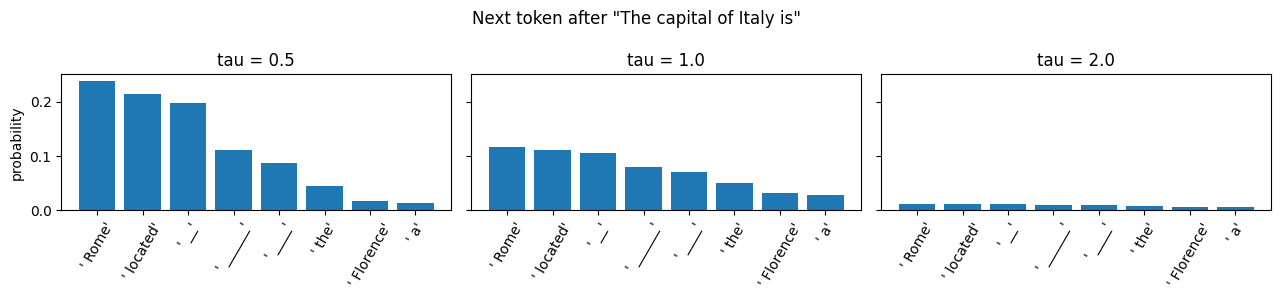

In [21]:
# Temperature on a real next-token distribution
prompt = 'The capital of Italy is'
x = tok(prompt, return_tensors='pt').input_ids.to(DEVICE)
with torch.no_grad():
    last = base(x).logits[0, -1]                        # logits of the last position only

fig, axes = plt.subplots(1, 3, figsize=(13, 3), sharey=True)
for ax, tau in zip(axes, [0.5, 1.0, 2.0]):
    p = F.softmax(last / tau, dim=-1)                   # divide by tau, then softmax
    top = torch.topk(p, 8)
    ax.bar([repr(tok.decode(i)) for i in top.indices], top.values.cpu())
    ax.set_title(f'tau = {tau}')
    ax.tick_params(axis='x', rotation=60)
axes[0].set_ylabel('probability')
plt.suptitle(f'Next token after "{prompt}"'); plt.tight_layout(); plt.show()

**What to look at:** at τ = 0.5 almost all the probability is on the first token (close to greedy). At τ = 2 the bars are flatter, so the unlikely tokens get chosen more often.

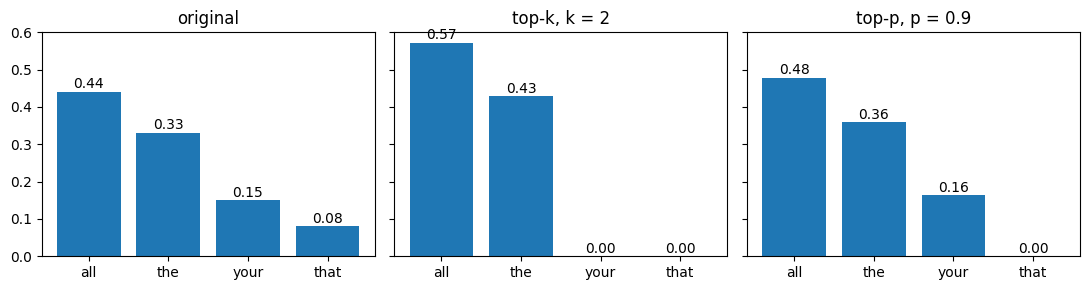

In [22]:
# Top-k and top-p, written as functions that set the cut logits to -inf
def filter_logits(logits, top_k=None, top_p=None):
    logits = logits.clone()
    if top_k is not None:                                   # top-k: a hard cut after the k-th token
        kth = torch.topk(logits, top_k).values[..., -1, None]
        logits[logits < kth] = -float('inf')
    if top_p is not None:                                   # top-p: smallest set with probability >= p
        sorted_logits, order = torch.sort(logits, descending=True)
        p = F.softmax(sorted_logits, dim=-1)
        mass_before = p.cumsum(-1) - p                      # probability of the tokens ranked above
        cut_sorted = mass_before >= top_p                   # the set is already complete without this token
        cut = torch.zeros_like(cut_sorted).scatter(-1, order, cut_sorted)
        logits[cut] = -float('inf')
    return logits                                           # softmax gives 0 to -inf: the same trick as the causal mask

# The 4-token example
words = ['all', 'the', 'your', 'that']
book_logits = torch.tensor([.44, .33, .15, .08]).log()
panels = {'original': {}, 'top-k, k = 2': dict(top_k=2), 'top-p, p = 0.9': dict(top_p=0.9)}

fig, axes = plt.subplots(1, 3, figsize=(11, 3), sharey=True)
for ax, (title, kw) in zip(axes, panels.items()):
    p = F.softmax(filter_logits(book_logits, **kw), dim=-1)
    ax.bar(words, p)
    for i, v in enumerate(p):
        ax.text(i, v + 0.01, f'{v:.2f}', ha='center')
    ax.set_title(title)
plt.tight_layout(); plt.show()

**What to look at:** Top-k keeps 2 tokens (.57, .43). Top-p keeps 3 tokens, because .44 + .33 = .77 is still below 0.9.

In [23]:
# Top-p adapts to how sure the model is, top-k does not
for prompt in ['The capital of Italy is', 'My favourite food is']:
    x = tok(prompt, return_tensors='pt').input_ids.to(DEVICE)
    with torch.no_grad():
        last = base(x).logits[0, -1]
    kept = torch.isfinite(filter_logits(last, top_p=0.9)).sum().item()
    print(f'{prompt!r:28} top-k = 50 keeps 50 tokens | top-p = 0.9 keeps {kept} tokens')

'The capital of Italy is'    top-k = 50 keeps 50 tokens | top-p = 0.9 keeps 53 tokens
'My favourite food is'       top-k = 50 keeps 50 tokens | top-p = 0.9 keeps 373 tokens


**What to look at:** when the next token is almost certain, top-p keeps very few tokens. When many continuations are fine, it keeps many more.

## 3 - The autoregressive loop

Generation is a loop: run the model, choose one token, add it to the input, repeat. Below, one function writes this loop by hand, in two versions:
- **without a cache:** every step runs the model again on the **whole** sequence;
- **with a KV cache:** the model returns the keys and values of all past tokens (`past_key_values`), so the next step only needs the **new** token.

Then we compare both with Hugging Face's built-in `model.generate()`.

In [25]:
# Choose one token from the logits of the last position
def pick(logits, temperature=0.0, top_k=None, top_p=None):
    if temperature == 0:                                     # greedy: the argmax token
        return logits.argmax(dim=-1, keepdim=True)
    logits = filter_logits(logits / temperature, top_k, top_p)
    return torch.multinomial(F.softmax(logits, dim=-1), num_samples=1)   # sample one token

EOS = base.generation_config.eos_token_id                    # the token that ends a document
EOS = set(EOS if isinstance(EOS, list) else [EOS])

# The autoregressive loop, by hand
@torch.no_grad()
def generate_manual(model, ids, max_new_tokens, use_cache=False, **decoding):
    x, past, input_lengths = ids, None, []
    for _ in range(max_new_tokens):
        out = model(x, past_key_values=past, use_cache=use_cache)
        input_lengths.append(x.shape[1])                     # how many tokens went into the model at this step
        next_id = pick(out.logits[:, -1, :], **decoding)     # logits of the last position only
        ids = torch.cat([ids, next_id], dim=1)               # add the token to the text
        if next_id.item() in EOS:
            break
        if use_cache:
            past, x = out.past_key_values, next_id           # KV cache: next input = only the new token
        else:
            x = ids                                          # no cache: next input = the whole sequence again
    return ids, input_lengths

In [29]:
# The same greedy text three ways, and how long each takes
PROMPT, N = 'The best thing about studying Large Language Models is', 100
ids = tok(PROMPT, return_tensors='pt').input_ids.to(DEVICE)

def timed(fn):
    if DEVICE == 'cuda': torch.cuda.synchronize()
    t0 = time.time(); result = fn()
    if DEVICE == 'cuda': torch.cuda.synchronize()
    return result, time.time() - t0

timed(lambda: generate_manual(base, ids, 5))                 # warm-up, not timed
(no_cache, len_no_cache), t_no_cache = timed(lambda: generate_manual(base, ids, N, use_cache=False))
(with_cache, len_cache),  t_cache    = timed(lambda: generate_manual(base, ids, N, use_cache=True))
builtin, t_builtin = timed(lambda: base.generate(ids, attention_mask=torch.ones_like(ids), max_new_tokens=N,
                                                 do_sample=False, pad_token_id=tok.eos_token_id))

def compare(a, b):
    n = min(a.shape[1], b.shape[1])
    diff = (a[0, :n] != b[0, :n]).nonzero()
    if len(diff) == 0 and a.shape[1] == b.shape[1]:
        return 'identical tokens'
    if len(diff) == 0:
        return f'same first {n} tokens, then one of them stops'
    return f'first difference at token {diff[0].item()} (rounding errors can flip two almost equal logits)'

new = ids.shape[1]
print(f'manual, no cache   : {t_no_cache:5.2f} s  ({no_cache.shape[1] - new} new tokens)')
print(f'manual, KV cache   : {t_cache:5.2f} s  | vs no cache: {compare(with_cache, no_cache)}')
print(f'model.generate()   : {t_builtin:5.2f} s  | vs no cache: {compare(builtin, no_cache)}')
print('\n--- greedy text ---')
print(tok.decode(no_cache[0]))

manual, no cache   :  3.80 s  (100 new tokens)
manual, KV cache   :  2.49 s  | vs no cache: identical tokens
model.generate()   :  2.79 s  | vs no cache: identical tokens

--- greedy text ---
The best thing about studying Large Language Models is that they are so easy to use. They are also so powerful. But they are also so easy to get wrong. This is because they are so easy to get wrong. This is because they are so easy to get wrong. This is because they are so easy to get wrong. This is because they are so easy to get wrong. This is because they are so easy to get wrong. This is because they are so easy to get wrong. This is because they are so easy to get wrong


- The three versions write **the same text**: `model.generate()` is this loop, plus many options.
- The cache makes the loop several times faster, and the gap grows with the length of the text.
- Greedy text from a base model often **repeats itself**: the same context gives the same choice, so a loop, once started, does not stop.

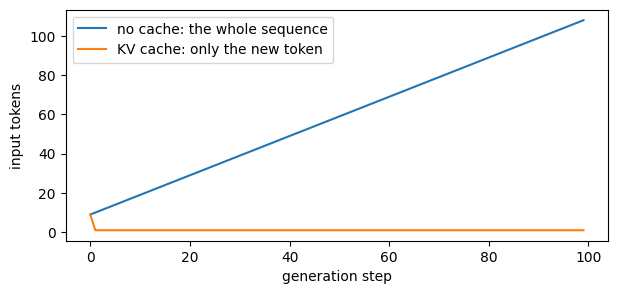

In [30]:
# What goes into the model at each step
plt.figure(figsize=(7, 3))
plt.plot(len_no_cache, label='no cache: the whole sequence')
plt.plot(len_cache, label='KV cache: only the new token')
plt.xlabel('generation step'); plt.ylabel('input tokens'); plt.legend(); plt.show()

Without a cache the input grows by one token at every step, so the work grows too. With the cache, after the first step (the prompt), the input is always 1 token. The price is memory: the cache keeps the keys and values of every past token.

In [31]:
# The same manual loop, now sampling with temperature and top-p
for seed in [0, 1]:
    torch.manual_seed(seed)
    out_ids, _ = generate_manual(base, ids, 60, use_cache=True, temperature=0.8, top_p=0.9)
    print(f'--- sample {seed} (temperature 0.8, top-p 0.9) ---')
    print(tok.decode(out_ids[0]), '\n')

--- sample 0 (temperature 0.8, top-p 0.9) ---
The best thing about studying Large Language Models is that you can make your own. You can train them yourself, using your own data, and then apply them to whatever task you need them for. Of course, you can do that with any tool you like, but what if you wanted to do that with a natural language tool like a chatbot 

--- sample 1 (temperature 0.8, top-p 0.9) ---
The best thing about studying Large Language Models is the flexibility of the language.
Let me explain.
The Natural Language Understanding (NLU) system in the transformers is based on a neural network, where the input to the network is text, the output is text. This is the first time the transformers were trained with text as input. It was trained 



**What to look at:** sampling breaks the repetition, and two seeds give two different texts. (Here we do not compare with `model.generate()`: with sampling, the two loops use the random numbers in a different order, so the texts differ even with the same seed.)

## 4 - Base vs instruct, prompting

Same prompts, two models. The base model only saw web text. The instruct model is the same network after post-training, and it receives the prompt inside its **chat template** (section 5).

In [34]:
# The base model continues the text, the instruct model answers
def complete(model, text, max_new_tokens=60):                # raw text in, continuation out
    x = tok(text, return_tensors='pt').to(DEVICE)
    out = model.generate(**x, max_new_tokens=max_new_tokens, pad_token_id=tok.eos_token_id)
    return tok.decode(out[0, x.input_ids.shape[1]:], skip_special_tokens=True).strip()

def chat(model, user, max_new_tokens=120):                   # the prompt goes into the chat template first
    text = tok.apply_chat_template([{'role': 'user', 'content': user}], tokenize=False, add_generation_prompt=True)
    return complete(model, text, max_new_tokens)

for prompt in ['Explain the moon landing to a six year old in a few sentences.',
               'Translate to Italian: The small dog']:
    print('PROMPT  :', prompt)
    print('BASE    :', complete(base, prompt))
    print('INSTRUCT:', chat(inst, prompt), '\n')

PROMPT  : Explain the moon landing to a six year old in a few sentences.
BASE    : The moon landing was a big moment in space history. It was when astronauts Neil Armstrong and Buzz Aldrin walked on the moon. It was a big moment for everyone on Earth. It was a big moment for everyone on Earth. It was a big moment for everyone on Earth. It was a big
INSTRUCT: Sure! Imagine you're looking up at the sky and seeing a beautiful, glowing ball of light called the Moon. It's like a big, round mirror that reflects the sun's rays onto Earth.

Now, imagine that one day, a very brave astronaut named Neil Armstrong stepped on this shiny, glowing ball of light. He looked down and saw it was perfectly round and smooth, just like a real moon. This made him feel very excited and proud!

After stepping on the Moon, he went back home with his friends and told everyone about what he saw. They were so happy because they had seen 

PROMPT  : Translate to Italian: The small dog
BASE    : is very friendly and

**What to look at:** the base model treats the prompt as the start of a document and continues it (another question, more text). The instruct model follows the instruction.

In [47]:
# Few-shot prompting. No weight changes: the examples are only in the context
few_shot = '''English: The cat
Italian: Il gatto

English: Good morning
Italian: Buongiorno

English: The small dog
Italian:'''
print('ZERO-SHOT:', complete(base, 'Translate to Italian: The small dog', 20).split('\n')[0])
print('FEW-SHOT :', complete(base, few_shot, 10).split('\n')[0])

ZERO-SHOT: is very friendly and loves to play with the other dogs.
FEW-SHOT : Il cane piccolo


**What to look at:** with two examples the base model copies the pattern and translates, with no post-training at all.

In [40]:
# Chain-of-Thought: more tokens before the answer
question = ('A bird eats 1/2 cup of food in the morning and 1/2 cup in the afternoon. '
            'How many cups does it eat in December, January and February (not a leap year)?')
print('DIRECT          :', chat(inst, question + ' Answer with only the number.', 250))
print('\nSTEP BY STEP    :', chat(inst, question + " Let's think step by step.", 500))

DIRECT          : To determine how much food the bird eats in December, January, and February (not a leap year), we need to calculate the total amount of food consumed over these three months.

First, let's find out how much food the bird eats in one month:
- In the morning, the bird eats \( \frac{1}{2} \) cup.
- In the afternoon, the bird eats another \( \frac{1}{2} \) cup.

So, the total amount of food eaten in one month is:
\[ \frac{1}{2} + \frac{1}{2} = 1 \text{ cup} \]

Since there are 3 months in December, January, and February, the total amount of food eaten in these three months is:
\[ 3 \times 1 = 3 \text{ cups} \]

Therefore, the total amount of food the bird eats in December, January, and February is \(\boxed{3}\).

STEP BY STEP    : To determine how much food a bird eats in December, January, and February (not a leap year), we need to calculate the total amount of food consumed over these three months.

First, let's break down the problem:

- **December**: The bird eats \( 

The right answer is 31 + 31 + 28 = 90 days × 1 cup = **90**. Compare the two answers: writing the steps first gives the model more computation before it commits to a number (still, a model can still make mistakes in calculations).

## 5 · Inside post-training

In [41]:
# Instruction Tuning: chat templates: a chat is a list of messages ...
messages = [
    {'role': 'system',    'content': 'You are a helpful assistant.'},
    {'role': 'user',      'content': 'Translate to Italian: The small dog'},
    {'role': 'assistant', 'content': 'Il cane piccolo'},
]
# ... and the template turns it into one string, with special tokens around each turn
print(tok.apply_chat_template(messages, tokenize=False))

<|im_start|>system
You are a helpful assistant.<|im_end|>
<|im_start|>user
Translate to Italian: The small dog<|im_end|>
<|im_start|>assistant
Il cane piccolo<|im_end|>



**What to look at:** `<|im_start|>` and `<|im_end|>` mark the start and end of each turn, followed by the role. This is the text the instruct model really reads.

In [42]:
# Instruction Tuning: the loss only on the response tokens (label -100 = ignored)
prompt_text = tok.apply_chat_template(messages[:-1], tokenize=False, add_generation_prompt=True)
full_text   = tok.apply_chat_template(messages, tokenize=False)
n_prompt = len(tok(prompt_text).input_ids)
sft_ids = tok(full_text, return_tensors='pt').input_ids.to(DEVICE)
labels = sft_ids.clone()
labels[:, :n_prompt] = -100                                    # cross_entropy skips -100

for i in range(n_prompt - 4, sft_ids.shape[1]):                # the last prompt tokens and the response
    t = sft_ids[0, i].item()
    print(f'{tok.decode(t)!r:22} label {labels[0, i].item():>7} | {"in the loss" if labels[0, i] != -100 else "ignored"}')

with torch.no_grad():
    for name, m in [('base', base), ('instruct', inst)]:
        print(f'SFT loss of the {name:8} model on this example: {m(sft_ids, labels=labels).loss.item():.2f}')

'\n'                   label    -100 | ignored
'<|im_start|>'         label    -100 | ignored
'assistant'            label    -100 | ignored
'\n'                   label    -100 | ignored
'Il'                   label   12050 | in the loss
' cane'                label   62235 | in the loss
' pic'                 label   10319 | in the loss
'colo'                 label   58248 | in the loss
'<|im_end|>'           label  151645 | in the loss
'\n'                   label     198 | in the loss
SFT loss of the base     model on this example: 4.95
SFT loss of the instruct model on this example: 0.52


**What to look at:** only the reply "Il cane piccolo" and its `<|im_end|>` count in the loss: the model learns to write answers, not to repeat questions. The loss is the same cross-entropy as pretraining, and the instruct model, trained on data like this, has a lower loss than the base model.

In [51]:
# LoRA: freeze W, train only the small matrices A and B on the attention projections
from peft import LoraConfig, get_peft_model

lora_cfg = LoraConfig(r=8, lora_alpha=16, target_modules=['q_proj', 'k_proj', 'v_proj', 'o_proj'], task_type='CAUSAL_LM')
lora_model = get_peft_model(copy.deepcopy(base), lora_cfg)
lora_model.print_trainable_parameters()

q = lora_model.base_model.model.model.layers[0].self_attn.q_proj
W, A, B = q.base_layer.weight, q.lora_A['default'].weight, q.lora_B['default'].weight
print(f'\nlayer 0, q_proj:  W {tuple(W.shape)} frozen = {W.numel():,} | '
      f'A {tuple(A.shape)} + B {tuple(B.shape)} trained = {A.numel() + B.numel():,}')

# B starts at zero, so AB = 0: before training, the LoRA model is exactly the base model
with torch.no_grad():
    print('largest difference of the logits vs the base model:', (lora_model(ids).logits - base(ids).logits).abs().max().item())
del lora_model

trainable params: 1,081,344 || all params: 495,114,112 || trainable%: 0.2184

layer 0, q_proj:  W (896, 896) frozen = 802,816 | A (8, 896) + B (896, 8) trained = 14,336
largest difference of the logits vs the base model: 0.0


**What to look at:** less than 1% of the parameters are trainable. For one matrix of 896 × 896, LoRA trains 8 · (896 + 896) numbers instead of 802,816. (PyTorch stores the matrices transposed, so the shapes are flipped with respect to the book.) The logits are identical at the start: B = 0, so training starts exactly from the base model.

In [53]:
# Learning from Preferences: Bradley-Terry, P(chosen > rejected) = sigmoid(score gap)
print(f"{'score gap z_w - z_l':>20} | {'P(chosen wins)':>14} | {'reward-model loss':>17}")
for gap in [-2, 0, 1, 2, 4]:
    g = torch.tensor(float(gap))
    print(f'{gap:20} | {torch.sigmoid(g).item():14.2f} | {-F.logsigmoid(g).item():17.2f}')

 score gap z_w - z_l | P(chosen wins) | reward-model loss
                  -2 |           0.12 |              2.13
                   0 |           0.50 |              0.69
                   1 |           0.73 |              0.31
                   2 |           0.88 |              0.13
                   4 |           0.98 |              0.02


**What to look at:** a gap of 0 means 50/50 and a loss of ln 2 = 0.69. The loss pushes the chosen answer's score above the rejected one; once the gap is large, the loss is almost 0.

In [52]:
# Alignment: the DPO loss, computed from log-probabilities of whole answers
def answer_logprob(model, prompt, answer):
    # log p(answer | prompt) = sum of log p over the answer tokens (the prompt is in the chat template)
    p_text = tok.apply_chat_template([{'role': 'user', 'content': prompt}], tokenize=False, add_generation_prompt=True)
    n_p = len(tok(p_text).input_ids)
    x = tok(p_text + answer + '<|im_end|>', return_tensors='pt').input_ids.to(DEVICE)
    with torch.no_grad():
        logp = F.log_softmax(model(x).logits[0, :-1], dim=-1)
    token_logp = logp.gather(-1, x[0, 1:, None])[:, 0]
    return token_logp[n_p - 1:].sum().item()

# Preference pairs
pairs = [
    ("I've heard garlic is a great natural antibiotic. Does it help with colds?",
     'It can be helpful against colds, but may make you stink.',
     'It might be one of the best natural antibiotics out there, so I think it would help if you have a cold.'),
    ('What is malaria?',
     'Here\'s an answer from a CDC page: "Malaria is a serious disease caused by a parasite that is spread through the bite of the mosquito."',
     "I don't know what malaria is."),
]

# We pretend: reference = base model, policy = instruct model
beta = 0.1
for prompt, chosen, rejected in pairs:
    r_w = beta * (answer_logprob(inst, prompt, chosen)   - answer_logprob(base, prompt, chosen))    # chosen: how much more likely
    r_l = beta * (answer_logprob(inst, prompt, rejected) - answer_logprob(base, prompt, rejected))  # rejected: how much more likely
    dpo = -F.logsigmoid(torch.tensor(r_w - r_l)).item()
    print(f'PROMPT: {prompt}')
    print(f'  chosen   moved by {r_w:+6.2f} | rejected moved by {r_l:+6.2f} | DPO loss {dpo:.2f}  (ln 2 = 0.69 = no preference)\n')

PROMPT: I've heard garlic is a great natural antibiotic. Does it help with colds?
  chosen   moved by  -0.17 | rejected moved by  +0.54 | DPO loss 1.11  (ln 2 = 0.69 = no preference)

PROMPT: What is malaria?
  chosen   moved by  +0.20 | rejected moved by  +0.93 | DPO loss 1.12  (ln 2 = 0.69 = no preference)



**What to look at:** "moved by" is β · (log p of the instruct model − log p of the base model): how much more likely post-training made each answer. DPO wants the chosen answer to move up **more** than the rejected one. Then the DPO loss is below 0.69.

**Question:** the DPO loss has the same form as the reward-model loss of the cell above. What plays the role of the score $z$?

## Summary

| Section | What you saw |
|---|---|
| 1 | The loss is the mean of −log p of the true next token; perplexity = exp(loss) |
| 2 | Temperature, top-k and top-p only change which logits survive before sampling |
| 3 | `generate()` is a loop; the KV cache makes each step cost one token |
| 4 | The base model continues text; examples or post-training make it follow instructions |
| 5 | Post-training uses the same model and the same kind of loss, on different data |